# Bước 1: Business Understanding & Analytic Approach
## UK Weather & Health: Weekly Deaths and Temperature (2016–2024)
---

> **Reproducibility / audit note (2026-11-13).** Run this notebook with the other notebooks and the five included data files in the **same directory**. Start with `Kernel > Restart & Run All`. The observed table has **442 real weeks**; the prepared regular grid has **469 weeks** (27 interpolated rows), and the forecasting table after lag-1 has **468 rows** (374 train / 94 observed test). This project analyzes association and **retrospective** forecasts—not causal effects or an operational heat-health warning. The original report-alignment figures and formulas are retained where they can be reproduced; any additional checks are labeled explicitly.

## 1.1 Research objective (paper-aligned)

**Research target:** forecast the number of weekly **registered all-cause deaths** in England & Wales using previous-week deaths, calendar month and (in a paired comparison) observed UK-average mean weekly maximum temperature.

**RQ1**: What seasonal and short-lag descriptive patterns connect deaths and temperature?

**RQ2**: Which regression design has the lowest held-out error compared with three simple time-series references?

**RQ3**: Does adding temperature improve forecast error consistently across temperature phases and robustness checks?

These are retrospective observational comparisons. The UK temperature series and England & Wales mortality series differ in geography; missing confounders rule out causal attribution.

## 1.2 Định nghĩa khái niệm

| Khái niệm | Ý nghĩa | Biến đại diện |
|---|---|---|
| **Physical Health (Weather)** | Đại diện bởi nhiệt độ tối đa | `tasmax_mean_weekly_degC` |
| **Mortality (Health outcome)** | Số lượng ca tử vong thực tế ghi nhận hàng tuần | `deaths_total` |

## 1.3 Exploratory IsSurge indicator (not a classification target in the submitted paper)

`IsSurge = 1` if the observed weekly deaths count is above its descriptive 75th-percentile threshold; otherwise it is `0`. This label is a summary/EDA flag and **not a validated medical safety threshold**. The submitted project does not fit or evaluate a supervised classification model; the target used for regression is `deaths_total`.

## 1.4 Prediction features and target

- **Target:** `deaths_total` for the target week.
- **Base features:** `lag_1_deaths` and 11 month dummy variables.
- **Optional feature:** `tasmax_mean_weekly_degC` (mean weekly maximum temperature, UK average).
- `tasmax_max_weekly_degC` is explored for collinearity but excluded from the paired paper-aligned regression.
- Target-week observed temperature is retrospective information, not necessarily available at the forecast issue time; a lagged-temperature sensitivity test addresses part of this limitation.

## 1.5 Methods actually implemented

| Method | Purpose | Evidence |
|---|---|---|
| SQL aggregation | Describe observed weekly mortality | Notebook 3 (442 observed weeks) |
| Python EDA | Seasonal, monthly and lag association | Notebook 4 |
| Visualization | Statistical charts, decomposition, regional Tmax context | Notebook 5 |
| Regression | OLS, polynomial-2, Ridge-2, Lasso-2; polynomial-3 complexity check | Notebook 6 |
| References | Last-value, seasonal-naive, damped-trend | Notebook 6 |
| Evaluation | MAE, RMSE, R², temperature phase comparison, robustness | Notebook 6 |

Classification is a potential future extension, not a completed outcome in this project.

## 1.6 Tổng quan Dataset

**Source file:** `uk_weather_health_weekly_2016_2024_TOTAL_FINAL.csv`

| Cột | Mô tả | Đơn vị |
|---|---|---|
| `week_start_sat` | Ngày bắt đầu tuần (Thứ Bảy) | date |
| `week_start_mon` | Ngày bắt đầu tuần (Thứ Hai) | date |
| `week_end` | Ngày kết thúc tuần (Thứ Sáu) | date |
| `deaths_total` | Tổng số ca tử vong toàn nguyên nhân (England & Wales) | count |
| `tasmax_mean_weekly_degC` | Nhiệt độ tối đa trung bình tuần (UK-average) | °C |
| `tasmax_max_weekly_degC` | Nhiệt độ tối đa cao nhất tuần (UK-average) | °C |

- **Khoảng thời gian:** 2016-01-02 → 2024-12-21 (442 tuần)
- **Mức tổng hợp:** Tuần, mức quốc gia
- **Data Dictionary:** `uk_weather_health_data_dictionary.csv`

## 1.7 Yếu tố nhiễu (Confounders)

 **Các đợt dịch bệnh** (như COVID-19 năm 2020) có thể làm dữ liệu tử vong tăng vọt **không do thời tiết**.

Các yếu tố nhiễu cần lưu ý:
- **Đại dịch COVID-19 (2020–2021):** Gây ra các đợt tử vong đột biến không liên quan đến nhiệt độ.
- **Mùa cúm (Flu season):** Trùng với mùa đông lạnh, gây nhiễu khi phân tích ảnh hưởng của nhiệt độ thấp.
- **Ô nhiễm không khí:** Thường tăng vào mùa đông, có thể góp phần vào tử vong nhưng không được đo trong dataset.
- **Thay đổi chính sách y tế:** Các biện pháp lockdown, tiêm vaccine có thể ảnh hưởng đến xu hướng tử vong.

## 1.8 Phương pháp luận dự án

```

  Bước 1. Business Understanding    →  Mục tiêu & cách tiếp cận    
  Bước 2. Data Collection           →  Thu thập, kiểm tra, làm sạch 
  Bước 3. Data Analysis (SQL)       →  Truy vấn tổng hợp           
  Bước 4. Data Analysis (Python)    →  Thống kê & EDA              
  Bước 5. Data Visualization        →  Biểu đồ & xu hướng          
  Bước 6. Regression Analysis       →  Mô hình hồi quy dự báo      

```

## 1.9 Deliverables and interpretation

1. Observed mortality–temperature merge (442 actual observed weeks).
2. Prepared regular weekly grid (469 rows including 27 interpolations) for lag creation.
3. SQL and Python descriptive association analyses from observed data.
4. Scientific figures and a regional temperature-only contextual plot.
5. Chronological forecasting comparison: three references vs four regression families and a degree-3 complexity test.
6. Cautious conclusion: degree-2 models attain the lowest point-estimate MAE on the reused holdout, but paired tests do **not** confirm clear superiority; temperature adds little to pooled accuracy.

Do not describe `IsSurge` clusters as medical risk, or temperature correlations as evidence of causality.

## 1.10 Đối chiếu với bài báo: Hình 2 — Quy trình phân tích sáu tầng

Phần này được **bổ sung để khớp trực tiếp với Hình 2 trong bài báo**. Nội dung gốc phía trên được giữ nguyên.

Hình mô tả toàn bộ dự án theo 6 tầng: **nguồn dữ liệu → chuẩn bị → mô tả → thiết lập tập huấn luyện/kiểm tra → mô hình dự báo → đánh giá**. Các ô màu san hô là những lựa chọn được bài báo nhấn mạnh vì chúng tạo khác biệt cho phép so sánh: nội suy 27 tuần, phân tích độ trễ và vùng, chia thời gian theo thứ tự, mô hình có thêm nhiệt độ, chia pha lạnh/vừa/ấm, loại nhóm biến và kiểm định Diebold–Mariano/Holm.


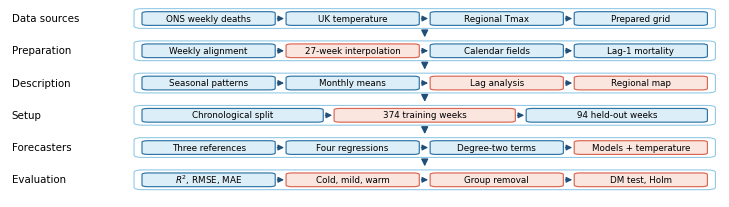

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import patches, colors
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

CORAL = '#F28E79'
CORAL_DARK = '#D96652'
BLUE = '#72B7D2'
BLUE_DARK = '#2D74A6'
BLUE_LIGHT = '#DCEEF7'
YELLOW = '#F7E7A9'
GREY = '#777777'
LIGHT_GREY = '#E6E6E6'
DARK = '#333333'

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.labelsize': 8, 'axes.titlesize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'axes.linewidth': 0.7,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.03,
})

rows = [
    ('Data sources', ['ONS weekly deaths', 'UK temperature', 'Regional Tmax', 'Prepared grid'], []),
    ('Preparation', ['Weekly alignment', '27-week interpolation', 'Calendar fields', 'Lag-1 mortality'], [1]),
    ('Description', ['Seasonal patterns', 'Monthly means', 'Lag analysis', 'Regional map'], [2, 3]),
    ('Setup', ['Chronological split', '374 training weeks', '94 held-out weeks'], [1]),
    ('Forecasters', ['Three references', 'Four regressions', 'Degree-two terms', 'Models + temperature'], [3]),
    ('Evaluation', ['$R^2$, RMSE, MAE', 'Cold, mild, warm', 'Group removal', 'DM test, Holm'], [1, 2, 3]),
]
fig, ax = plt.subplots(figsize=(7.35, 2.10))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
outer_x, outer_w, outer_h, inner_h = 0.185, 0.795, 0.090, 0.062
top, row_gap, horizontal_gap, inner_pad = 0.920, 0.160, 0.021, 0.010
arrow_color = '#1F4E79'
for r, (label, boxes, coral_idx) in enumerate(rows):
    y = top - r * row_gap
    ax.text(0.012, y, label, ha='left', va='center', fontsize=7.4)
    ax.add_patch(patches.FancyBboxPatch(
        (outer_x, y - outer_h/2), outer_w, outer_h,
        boxstyle='round,pad=0.004,rounding_size=0.012',
        facecolor='white', edgecolor='#8CC6E4', linewidth=0.75, zorder=1))
    n = len(boxes)
    box_w = (outer_w - 2*inner_pad - (n-1)*horizontal_gap) / n
    xs = [outer_x + inner_pad + i*(box_w + horizontal_gap) for i in range(n)]
    for i, (x, text_box) in enumerate(zip(xs, boxes)):
        face = '#FBE5DF' if i in coral_idx else BLUE_LIGHT
        edge = CORAL_DARK if i in coral_idx else BLUE_DARK
        ax.add_patch(patches.FancyBboxPatch(
            (x, y-inner_h/2), box_w, inner_h,
            boxstyle='round,pad=0.003,rounding_size=0.008',
            facecolor=face, edgecolor=edge, linewidth=0.85, zorder=2))
        ax.text(x+box_w/2, y, text_box, ha='center', va='center', fontsize=6.35, zorder=5)
        if i < n-1:
            ax.add_patch(patches.FancyArrowPatch(
                (x+box_w+0.002, y), (xs[i+1]-0.002, y), arrowstyle='-|>',
                mutation_scale=8.5, linewidth=0.85, color=arrow_color, zorder=4))
    if r < len(rows)-1:
        next_y = top - (r+1)*row_gap
        xmid = outer_x + outer_w/2
        ax.add_patch(patches.FancyArrowPatch(
            (xmid, y-outer_h/2-0.008), (xmid, next_y+outer_h/2+0.008),
            arrowstyle='-|>', mutation_scale=10.5, linewidth=0.95,
            color=arrow_color, zorder=6))
fig.subplots_adjust(left=0.01, right=0.995, bottom=0.03, top=0.99)
plt.show()


### Cách đọc Hình 2 khi báo cáo

- Dữ liệu quan sát có **442 tuần**; sau khi tạo lưới tuần liên tục có **469 tuần**, tức bổ sung **27 tuần bằng nội suy tuyến tính**.
- Sau khi tạo biến `lag_1_deaths`, bảng mô hình còn **468 dòng**.
- Chia theo thời gian, không xáo trộn: **374 tuần huấn luyện** và **94 tuần kiểm tra**.
- Khối kiểm tra chung kéo dài từ **13/03/2023 đến 23/12/2024** và được dùng cho mọi mô hình và mốc tham chiếu để so sánh công bằng.
- Hình này là **sơ đồ phương pháp luận**, không có nghĩa mỗi ô là một mô hình riêng.


## Final checks / Verification

The following assertions are executable checks, not manually entered model results.

In [2]:
assert len(rows)==6
print('PASS: six-stage research pipeline is defined.')

PASS: six-stage research pipeline is defined.
